In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("dirty_cafe_sales.csv")
print(df.shape)
df.head(10)

(10000, 8)


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,NaN,2023-03-31
6,TXN_4433211,UNKNOWN,3,3.0,9.0,ERROR,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,UNKNOWN,2023-10-28
8,TXN_4717867,NaN,5,3.0,15.0,NaN,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5,4.0,20.0,NaN,In-store,2023-12-31


In [ ]:
df.info()
print("\n--- Null counts ---")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB

--- Null counts ---
Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Transaction IDs:", df['Transaction ID'].duplicated().sum())

print("\n--- ERROR / UNKNOWN counts per column ---")
for col in df.columns:
    bad = df[col].isin(['ERROR', 'UNKNOWN']).sum()
    print(f"{col}: {bad}")

Duplicate rows: 0
Duplicate Transaction IDs: 0

--- ERROR / UNKNOWN counts per column ---
Transaction ID: 0
Item: 636
Quantity: 341
Price Per Unit: 354
Total Spent: 329
Payment Method: 599
Location: 696
Transaction Date: 301


In [ ]:
for col in ['Item', 'Payment Method', 'Location']:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


Item:
Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
NaN          333
ERROR        292
Name: count, dtype: int64

Payment Method:
Payment Method
NaN               2579
Digital Wallet    2291
Credit Card       2273
Cash              2258
ERROR              306
UNKNOWN            293
Name: count, dtype: int64

Location:
Location
NaN         3265
Takeaway    3022
In-store    3017
ERROR        358
UNKNOWN      338
Name: count, dtype: int64


### Data Quality Report: Summary
- Total rows: 10,000 | Columns: 8
- Duplicate rows: 0 | Duplicate Transaction IDs: 0
- All columns are stored as `object` (text), because of "ERROR" / "UNKNOWN" values mixed with numbers and dates
- Hidden missing values ("ERROR", "UNKNOWN") exist in every column except Transaction ID
- Most affected columns (null + ERROR/UNKNOWN):
  - Location: 3,961 (~40%)
  - Payment Method: 3,178 (~32%)
  - Item: 969 (~10%)
- Next step: handle missing values

In [ ]:
df = df.replace(['ERROR', 'UNKNOWN'], np.nan)

print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

Transaction ID         0
Item                 969
Quantity             479
Price Per Unit       533
Total Spent          502
Payment Method      3178
Location            3961
Transaction Date     460
dtype: int64

Total missing values: 10082


In [ ]:
num_cols = ['Quantity', 'Price Per Unit', 'Total Spent']
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors='coerce')

print(df[num_cols].dtypes)
print("\n--- Unique Price Per Unit values for each Item ---")
print(df.groupby('Item')['Price Per Unit'].unique())

Quantity          float64
Price Per Unit    float64
Total Spent       float64
dtype: object

--- Unique Price Per Unit values for each Item ---
Item
Cake        [3.0, nan]
Coffee      [2.0, nan]
Cookie      [1.0, nan]
Juice       [3.0, nan]
Salad       [5.0, nan]
Sandwich    [4.0, nan]
Smoothie    [4.0, nan]
Tea         [1.5, nan]
Name: Price Per Unit, dtype: object


In [ ]:
# Rule 1: fill missing Price Per Unit using the fixed price of each Item
price_map = {'Coffee': 2.0, 'Cookie': 1.0, 'Tea': 1.5, 'Salad': 5.0,
             'Cake': 3.0, 'Juice': 3.0, 'Sandwich': 4.0, 'Smoothie': 4.0}

before = df[['Price Per Unit', 'Quantity', 'Total Spent']].isnull().sum()

mask = df['Price Per Unit'].isnull() & df['Item'].notnull()
df.loc[mask, 'Price Per Unit'] = df.loc[mask, 'Item'].map(price_map)

# Rule 2: Total Spent = Quantity * Price Per Unit (recover whichever one is missing)
mask = df['Total Spent'].isnull() & df['Quantity'].notnull() & df['Price Per Unit'].notnull()
df.loc[mask, 'Total Spent'] = df.loc[mask, 'Quantity'] * df.loc[mask, 'Price Per Unit']

mask = df['Quantity'].isnull() & df['Total Spent'].notnull() & df['Price Per Unit'].notnull()
df.loc[mask, 'Quantity'] = df.loc[mask, 'Total Spent'] / df.loc[mask, 'Price Per Unit']

mask = df['Price Per Unit'].isnull() & df['Total Spent'].notnull() & df['Quantity'].notnull()
df.loc[mask, 'Price Per Unit'] = df.loc[mask, 'Total Spent'] / df.loc[mask, 'Quantity']

after = df[['Price Per Unit', 'Quantity', 'Total Spent']].isnull().sum()
print(pd.DataFrame({'before': before, 'after': after}))

                before  after
Price Per Unit     533      6
Quantity           479     23
Total Spent        502     23


In [ ]:
# 1. Recover missing Item from unique prices
unique_price_item = {2.0: 'Coffee', 1.0: 'Cookie', 1.5: 'Tea', 5.0: 'Salad'}
mask = df['Item'].isnull() & df['Price Per Unit'].isin(unique_price_item.keys())
df.loc[mask, 'Item'] = df.loc[mask, 'Price Per Unit'].map(unique_price_item)
print("Items recovered:", mask.sum())

# 2. Fill remaining categorical nulls with an explicit 'Unknown' category
for col in ['Item', 'Payment Method', 'Location']:
    df[col] = df[col].fillna('Unknown')

# 3. Drop rows where core numeric fields cannot be recovered
rows_before = len(df)
df = df.dropna(subset=['Quantity', 'Price Per Unit', 'Total Spent']).reset_index(drop=True)
print("Rows dropped:", rows_before - len(df), "| Rows remaining:", len(df))

print("\nRemaining nulls:")
print(df.isnull().sum())

Items recovered: 489
Rows dropped: 26 | Rows remaining: 9974

Remaining nulls:
Transaction ID        0
Item                  0
Quantity              0
Price Per Unit        0
Total Spent           0
Payment Method        0
Location              0
Transaction Date    460
dtype: int64


### Missing Value Strategy
- **Quantity / Price Per Unit / Total Spent:** recovered using business logic (fixed price per item, and Total Spent = Quantity x Price Per Unit). Missing values dropped from 533 / 479 / 502 to 6 / 23 / 23 before the final step. The 26 rows that still could not be recovered were dropped, since they cannot be estimated reliably (0.26% of the data).
- **Item:** 489 values recovered where the price uniquely identifies the item (2.0, 1.0, 1.5, 5.0). The remaining ones were labelled "Unknown".
- **Payment Method and Location:** 30-40% of values were missing, so imputing with the mode would introduce bias and dropping rows would remove too much data. Labelled "Unknown" instead.
- **Transaction Date:** 460 nulls remain and are handled in the data type correction phase.

In [ ]:
dup_rows = df.duplicated().sum()
dup_ids = df['Transaction ID'].duplicated().sum()
print("Duplicate rows:", dup_rows)
print("Duplicate Transaction IDs:", dup_ids)

df = df.drop_duplicates().reset_index(drop=True)
print("Rows after duplicate removal:", len(df))

Duplicate rows: 0
Duplicate Transaction IDs: 0
Rows after duplicate removal: 9974


### Duplicate Removal
Checked for fully duplicate rows and duplicate Transaction IDs. Both counts were 0, so no rows were removed. Transaction ID is a unique key in this dataset.

In [ ]:
# 1. Strip extra whitespace and standardise text format
text_cols = ['Item', 'Payment Method', 'Location']
for col in text_cols:
    df[col] = df[col].str.strip().str.title()

for col in text_cols:
    print(f"{col}: {sorted(df[col].unique())}")

# 2. Check Transaction ID pattern
valid_id = df['Transaction ID'].str.match(r'^TXN_\d{7}$')
print("\nInvalid Transaction IDs:", (~valid_id).sum())

# 3. Check Transaction Date format (YYYY-MM-DD)
date_str = df['Transaction Date'].dropna().astype(str)
valid_date = date_str.str.match(r'^\d{4}-\d{2}-\d{2}$')
print("Dates not in YYYY-MM-DD format:", (~valid_date).sum())

Item: ['Cake', 'Coffee', 'Cookie', 'Juice', 'Salad', 'Sandwich', 'Smoothie', 'Tea', 'Unknown']
Payment Method: ['Cash', 'Credit Card', 'Digital Wallet', 'Unknown']
Location: ['In-Store', 'Takeaway', 'Unknown']

Invalid Transaction IDs: 0
Dates not in YYYY-MM-DD format: 0


### Standardisation
- Stripped leading/trailing whitespace and applied consistent title case to Item, Payment Method and Location.
- Verified that all Transaction IDs follow the pattern TXN_ followed by 7 digits.
- Verified that all Transaction Dates use the YYYY-MM-DD format.
- Category values were already consistent (no spelling variants such as "cash" / "Cash"), so no value mapping was needed.

In [ ]:
# Transaction Date -> datetime
df['Transaction Date'] = pd.to_datetime(df['Transaction Date'], format='%Y-%m-%d', errors='coerce')

# Quantity -> integer (check first that all values are whole numbers)
print("Non-integer quantities:", (df['Quantity'] % 1 != 0).sum())
df['Quantity'] = df['Quantity'].round().astype(int)

# Transaction ID -> string, categorical columns -> category
df['Transaction ID'] = df['Transaction ID'].astype('string')
for col in ['Item', 'Payment Method', 'Location']:
    df[col] = df[col].astype('category')

# Money columns stay as float
df[['Price Per Unit', 'Total Spent']] = df[['Price Per Unit', 'Total Spent']].astype(float)

print("\n--- Final data types ---")
print(df.dtypes)
print("\nMissing Transaction Dates:", df['Transaction Date'].isnull().sum())

Non-integer quantities: 0

--- Final data types ---
Transaction ID      string[python]
Item                      category
Quantity                     int64
Price Per Unit             float64
Total Spent                float64
Payment Method            category
Location                  category
Transaction Date    datetime64[ns]
dtype: object

Missing Transaction Dates: 460


### Data Type Correction
- Transaction Date converted from text to datetime.
- Quantity converted from float to integer (all values were verified to be whole numbers).
- Transaction ID converted to string; Item, Payment Method and Location converted to category.
- Price Per Unit and Total Spent kept as float (monetary values).
- Missing Transaction Dates (about 4.6% of rows) were kept as NaT. The date cannot be reliably inferred from other columns, and dropping these rows would discard otherwise valid sales records.

Quantity: min=1, max=5, bounds=(-1.00, 7.00), outliers=0
Price Per Unit: min=1.0, max=5.0, bounds=(-1.00, 7.00), outliers=0
Total Spent: min=1.0, max=25.0, bounds=(-8.00, 24.00), outliers=268


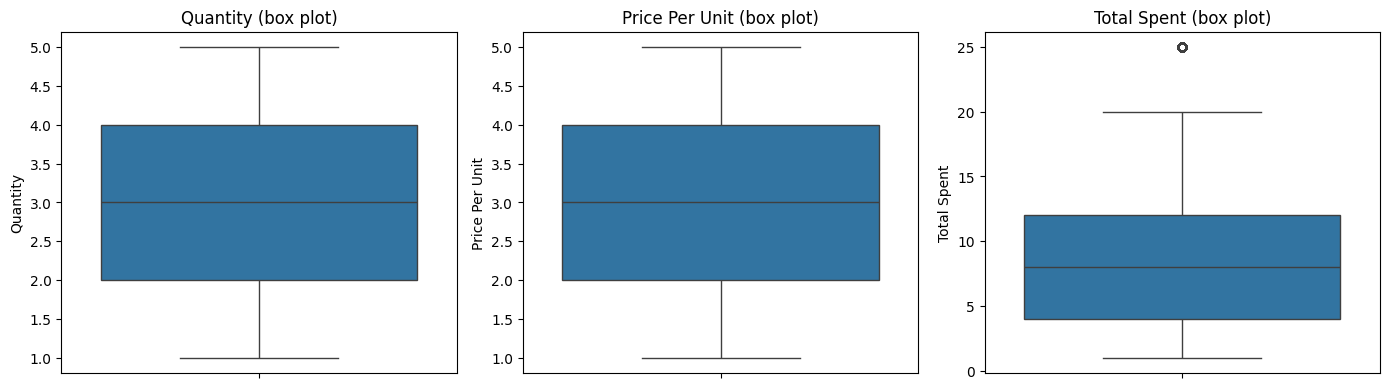


Rows where Total Spent != Quantity x Price Per Unit: 0


In [ ]:
num_cols = ['Quantity', 'Price Per Unit', 'Total Spent']

# 1. IQR outlier detection
for col in num_cols:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: min={df[col].min()}, max={df[col].max()}, "
          f"bounds=({lower:.2f}, {upper:.2f}), outliers={n_out}")

# 2. Box plots
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"{col} (box plot)")
plt.tight_layout()
plt.show()

# 3. Consistency check: Total Spent = Quantity * Price Per Unit
mismatch = (df['Total Spent'] != df['Quantity'] * df['Price Per Unit']).sum()
print("\nRows where Total Spent != Quantity x Price Per Unit:", mismatch)

In [ ]:
high = df[df['Total Spent'] > 24]
print("Rows above IQR upper bound:", len(high))
print(high.groupby(['Item', 'Quantity'], observed=True).size())

Rows above IQR upper bound: 268
Item   Quantity
Salad  5           268
dtype: int64


### Outlier Detection
- Method: IQR (1.5 x IQR rule) on Quantity, Price Per Unit and Total Spent, plus box plots.
- Quantity (1-5) and Price Per Unit (1.0-5.0): no outliers.
- Total Spent: 268 values above the IQR upper bound (24.0), with a maximum of 25.0.
- Decision: **retained**. These values equal Quantity x Price Per Unit for large orders (for example 5 salads at 5.0 each), so they are valid transactions and not data errors. Removing or capping them would distort revenue figures.
- Consistency check: Total Spent equals Quantity x Price Per Unit in all rows (0 mismatches).

                                   Metric  Before  After
                                Row count   10000   9974
             Missing / placeholder values   10082   8054
                           Duplicate rows       0      0
Columns with correct data type (out of 8)       4      8


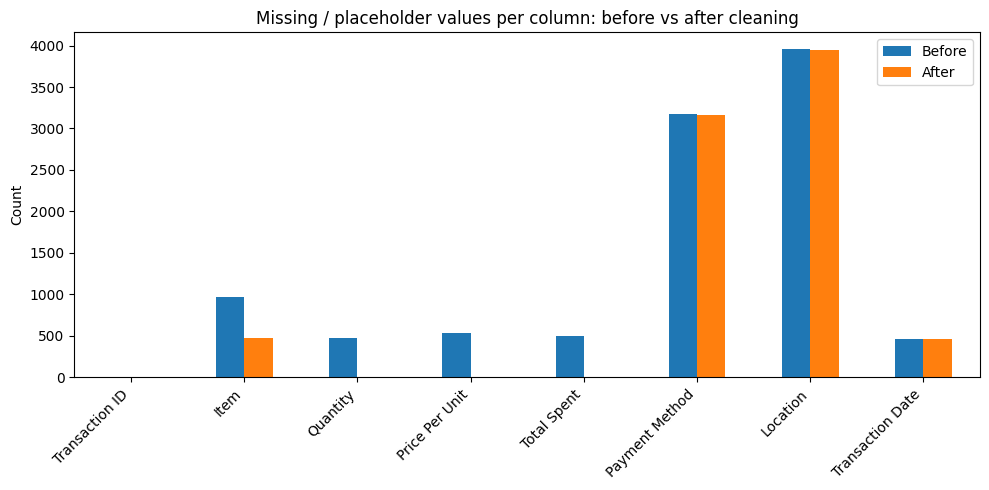

In [ ]:
# Reload the raw data for the "before" snapshot
df_raw = pd.read_csv("dirty_cafe_sales.csv")
cat_cols = ['Item', 'Payment Method', 'Location']

# Missing / placeholder values per column
before_missing = df_raw.replace(['ERROR', 'UNKNOWN'], np.nan).isnull().sum()

after_missing = {}
for col in df.columns:
    n = df[col].isnull().sum()
    if col in cat_cols:
        n += (df[col] == 'Unknown').sum()
    after_missing[col] = n
after_missing = pd.Series(after_missing)

# Columns with the correct data type (text columns count as correct before)
before_ok = 4 + sum([
    pd.api.types.is_numeric_dtype(df_raw['Quantity']),
    pd.api.types.is_numeric_dtype(df_raw['Price Per Unit']),
    pd.api.types.is_numeric_dtype(df_raw['Total Spent']),
    pd.api.types.is_datetime64_any_dtype(df_raw['Transaction Date']),
])
after_ok = 4 + sum([
    pd.api.types.is_numeric_dtype(df['Quantity']),
    pd.api.types.is_numeric_dtype(df['Price Per Unit']),
    pd.api.types.is_numeric_dtype(df['Total Spent']),
    pd.api.types.is_datetime64_any_dtype(df['Transaction Date']),
])

summary = pd.DataFrame({
    'Metric': ['Row count', 'Missing / placeholder values',
               'Duplicate rows', 'Columns with correct data type (out of 8)'],
    'Before': [len(df_raw), before_missing.sum(),
               df_raw.duplicated().sum(), before_ok],
    'After':  [len(df), after_missing.sum(),
               df.duplicated().sum(), after_ok],
})
print(summary.to_string(index=False))

# Chart: missing / placeholder values per column, before vs after
compare = pd.DataFrame({'Before': before_missing, 'After': after_missing})
compare.plot(kind='bar', figsize=(10, 5))
plt.title("Missing / placeholder values per column: before vs after cleaning")
plt.ylabel("Count")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("before_after_missing.png", dpi=150)
plt.show()

In [ ]:
print(compare.to_string())

                  Before  After
Transaction ID         0      0
Item                 969    474
Quantity             479      0
Price Per Unit       533      0
Total Spent          502      0
Payment Method      3178   3168
Location            3961   3952
Transaction Date     460    460


### Before vs After Summary
| Metric | Before | After |
|---|---|---|
| Row count | 10,000 | 9,974 |
| Missing / placeholder values | 10,082 | 8,054 |
| Duplicate rows | 0 | 0 |
| Columns with correct data type (out of 8) | 4 | 8 |

**Missing / placeholder values per column**
| Column | Before | After |
|---|---|---|
| Item | 969 | 474 |
| Quantity | 479 | 0 |
| Price Per Unit | 533 | 0 |
| Total Spent | 502 | 0 |
| Payment Method | 3,178 | 3,168 |
| Location | 3,961 | 3,952 |
| Transaction Date | 460 | 460 |

**Key observations**
- Quantity, Price Per Unit and Total Spent now have **zero** missing values. Most were recovered using business logic, and only 26 rows (0.26%) were dropped.
- Item missing values were cut roughly in half (969 to 474) by inferring the item from its unique price.
- All 8 columns now have the correct data type.
- The remaining 8,054 values are labelled "Unknown" (Item, Payment Method, Location) or left as missing dates (460). They were kept on purpose: Payment Method and Location are missing in 30-40% of rows, so imputing would introduce bias and dropping would remove a large share of valid sales records.
- No duplicate rows were found, so none were removed.

In [ ]:
df.to_csv("cleaned_cafe_sales.csv", index=False)
print("Saved:", df.shape)

from google.colab import files
files.download("cleaned_cafe_sales.csv")
files.download("before_after_missing.png")

Saved: (9974, 8)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>